变量说明：
- subscriberID="个人客户的ID"
- churn="是否流失：1=流失";
- gender="性别"
- Age="年龄"
- edu_class="教育水平"
- incomeCode="用户居住区域平均收入的代码"
- duration="在网时长"
- feton="是否注册飞信"
- peakMinAv="统计期间内最高单月通话时长"
- peakMinDiff="统计期间结束月份与开始月份相比通话时长增加数量"
- posTrend="该用户通话时长是否呈现出上升态势：是=1"
- negTrend="该用户通话时长是否呈现出下降态势：是=1"
- nrProm="电话公司营销的数量"
- prom="最近一个月是否被营销过：是=1"
- curPlan="统计时间开始时套餐类型：1=最高通过200分钟；2=300分钟；3=350分钟；4=500分钟"
- avgplan="统计期间内平均套餐类型"
- planChange="统计期间是否更换过套餐：1=是"
- posPlanChange="统计期间是否提高套餐：1=是"
- negPlanChange="统计期间是否降低套餐：1=是"
- call_10086="拨打10086的次数"

In [2]:
import os
import numpy as np
from scipy import stats
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

## 导入数据

In [3]:
churn = pd.read_csv('telecom_churn.csv')   
churn.head()

,subscriberID,churn,gender,AGE,edu_class,incomeCode,duration,feton,peakMinAv,peakMinDiff,posTrend,negTrend,nrProm,prom,curPlan,avgplan,planChange,posPlanChange,negPlanChange,call_10086
0,19164958.0,1.0,0.0,20.0,2.0,12.0,16.0,0.0,113.666667,-8.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,39244924.0,1.0,1.0,20.0,0.0,21.0,5.0,0.0,274.000000,-371.0,0.0,1.0,2.0,1.0,3.0,2.0,2.0,1.0,0.0,1.0
2,39578413.0,1.0,0.0,11.0,1.0,47.0,3.0,0.0,392.000000,-784.0,0.0,1.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,1.0
3,40992265.0,1.0,0.0,43.0,0.0,4.0,12.0,0.0,31.000000,-76.0,0.0,1.0,2.0,1.0,3.0,3.0,0.0,0.0,0.0,1.0
4,43061957.0,1.0,1.0,60.0,0.0,9.0,14.0,0.0,129.333333,-334.0,0.0,1.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0


In [4]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3463 entries, 0 to 3462
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subscriberID   3463 non-null   float64
 1   churn          3463 non-null   float64
 2   gender         3463 non-null   float64
 3   AGE            3463 non-null   float64
 4   edu_class      3463 non-null   float64
 5   incomeCode     3463 non-null   float64
 6   duration       3463 non-null   float64
 7   feton          3463 non-null   float64
 8   peakMinAv      3463 non-null   float64
 9   peakMinDiff    3463 non-null   float64
 10  posTrend       3463 non-null   float64
 11  negTrend       3463 non-null   float64
 12  nrProm         3463 non-null   float64
 13  prom           3463 non-null   float64
 14  curPlan        3463 non-null   float64
 15  avgplan        3463 non-null   float64
 16  planChange     3463 non-null   float64
 17  posPlanChange  3463 non-null   float64
 18  negPlanC

# 分类变量的相关关系

## 交叉表

In [5]:
# normalize=False默认计算频数
cross_table = pd.crosstab(churn.posTrend, churn.churn, margins=True)
cross_table

churn,0.0,1.0,All
posTrend,,,
0.0,829,990,1819
1.0,1100,544,1644
All,1929,1534,3463


In [6]:
def percConvert(ser):
    return ser/float(ser[-1])

cross_table.apply(percConvert, axis = 1)

churn,0.0,1.0,All
posTrend,,,
0.0,0.455745,0.544255,1.0
1.0,0.669100,0.330900,1.0
All,0.557031,0.442969,1.0


In [7]:
544/1644

0.3309002433090024

## 卡方检验

In [7]:
#列联表的卡方独立性检验：显著，说明二者存在相关关系
print('''chisq = %6.4f 
p-value = %6.4f
dof = %i 
expected_freq = %s'''  %stats.chi2_contingency(cross_table.iloc[:2, :2]))

chisq = 158.4433 
p-value = 0.0000
dof = 1 
expected_freq = [[1013.24025411  805.75974589]
 [ 915.75974589  728.24025411]]


# 一元逻辑回归

## 划分训练集与测试集

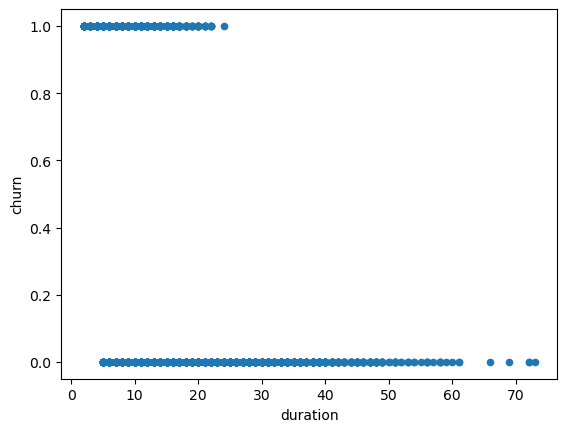

In [8]:
#在网时长与是否流失
churn.plot(x='duration', y='churn', kind='scatter');

In [15]:
# 随机抽样，建立训练集与测试集
train = churn.sample(frac=0.7, random_state=666).copy()
test = churn[~ churn.index.isin(train.index)].copy()
print(' 训练集样本量: %i \n 测试集样本量: %i' %(len(train), len(test)))

 训练集样本量: 2424 
 测试集样本量: 1039


## 建立模型

In [16]:
#建模
lg = smf.logit('churn ~ duration', train).fit()
lg.summary()

Optimization terminated successfully.
         Current function value: 0.434302
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                 2424
Model:                          Logit   Df Residuals:                     2422
Method:                           MLE   Df Model:                            1
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.3657
Time:                        10:13:38   Log-Likelihood:                -1052.7
converged:                       True   LL-Null:                       -1659.8
Covariance Type:            nonrobust   LLR p-value:                5.281e-266
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.5597      0.120     21.365      0.000       2.325       2.794
duration      -0.2487      0.011    -22.035      0.000      -0.271      -0.227
==============================================================================
"""

## 模型预测

In [22]:
#预测（概率）
train['proba'] = lg.predict(train)
test['proba'] = lg.predict(test)

In [18]:
test[['churn','proba']].head()

,churn,proba
3,1.0,0.395387
4,1.0,0.284526
5,0.0,0.579658
9,1.0,0.158662
12,0.0,0.518160


## 模型评估

In [19]:
import sklearn.metrics as metrics

In [20]:
#设置阈值
test['prediction'] = (test['proba'] > 0.3).astype('int')

In [21]:
test[['churn','prediction']].head(10)

,churn,prediction
3,1.0,1
4,1.0,0
5,0.0,1
9,1.0,0
12,0.0,1
14,0.0,0
16,1.0,1
17,1.0,1
20,1.0,1
22,0.0,0


In [24]:
#混淆矩阵
pd.crosstab(test.churn, test.prediction, margins=True)

prediction,0,1,All
churn,,,
0.0,340,220,560
1.0,42,437,479
All,382,657,1039


In [23]:
#计算准确率
acc = sum(test['prediction'] == test['churn']) /len(test)
print('The accurancy is %.2f' %acc)

The accurancy is 0.75


In [25]:
#ROC曲线
for i in np.arange(0.1, 0.9, 0.1):
    prediction = (test['proba'] > i).astype('int')
    confusion_matrix = pd.crosstab(prediction,test.churn,
                                   margins = True)
    precision = confusion_matrix.loc[0, 0] /confusion_matrix.loc['All', 0]
    recall = confusion_matrix.loc[0, 0] / confusion_matrix.loc[0, 'All']
    Specificity = confusion_matrix.loc[1, 1] /confusion_matrix.loc[1,'All']
    f1_score = 2 * (precision * recall) / (precision + recall)
    print('threshold: %s, precision: %.2f, recall:%.2f ,Specificity:%.2f , f1_score:%.2f'%(i, precision, recall, Specificity,f1_score))

threshold: 0.1, precision: 0.45, recall:0.97 ,Specificity:0.61 , f1_score:0.62
threshold: 0.2, precision: 0.56, recall:0.93 ,Specificity:0.65 , f1_score:0.69
threshold: 0.30000000000000004, precision: 0.61, recall:0.89 ,Specificity:0.67 , f1_score:0.72
threshold: 0.4, precision: 0.69, recall:0.83 ,Specificity:0.70 , f1_score:0.75
threshold: 0.5, precision: 0.74, recall:0.79 ,Specificity:0.72 , f1_score:0.77
threshold: 0.6, precision: 0.83, recall:0.74 ,Specificity:0.77 , f1_score:0.78
threshold: 0.7000000000000001, precision: 0.94, recall:0.70 ,Specificity:0.89 , f1_score:0.80
threshold: 0.8, precision: 1.00, recall:0.63 ,Specificity:1.00 , f1_score:0.78


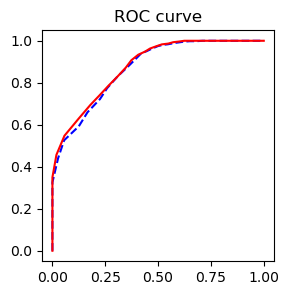

In [26]:
fpr_test, tpr_test, th_test = metrics.roc_curve(test.churn, test.proba)
fpr_train, tpr_train, th_train = metrics.roc_curve(train.churn, train.proba)

plt.figure(figsize=[3, 3])
plt.plot(fpr_test, tpr_test, 'b--')
plt.plot(fpr_train, tpr_train, 'r-')
plt.title('ROC curve')
plt.show()

In [27]:
print('AUC = %.4f' %metrics.auc(fpr_test, tpr_test))

AUC = 0.8680


In [28]:
#最优阈值（约登指数）
th_test[(tpr_test - fpr_test).argmax()]

0.45610676187868604

# 多元逻辑回归

## 特征选择

### 连续变量选择

前向回归、后向回归、逐步回归：
- 前向回归：Y和每个X做回归，选择解释力度最高的（R方、p_value、AIC、BIC），第一个变量进入回归方程，进行F检验和t检验，同时计算残差平方和s1，通过检验则保留；引入第二个变量，重新构建方程与检验，计算残差平方和s2，比较s1与s2，s1-s2（偏回归平方和）
- 后向回归：与前向回归相反，所有变量一次进入，进行检验，根据偏回归平方和逐个剔除
- 逐步回归：结合两者，变量一个个进入，引入新变量要进行检验，通过才加入，引入新变量后要对原变量重新进行检验，一旦不显著则剔除

In [22]:
# model = smf.glm(
#         formula=formula, data=data, 
#         family=sm.families.Binomial(sm.families.links.logit)
#     ).fit()

In [23]:
#向前法
def forward_select(data, response):
    remaining = set(data.columns)
    remaining.remove(response)
    selected = []
    current_score, best_new_score = float('inf'), float('inf')
    while remaining:
        aic_with_candidates=[]
        for candidate in remaining:
            formula = "{} ~ {}".format(
                response,' + '.join(selected + [candidate]))
            aic = smf.logit(
                formula=formula, data=data).fit().aic
            aic_with_candidates.append((aic, candidate))
        aic_with_candidates.sort(reverse=True)
        best_new_score, best_candidate=aic_with_candidates.pop()
        if current_score > best_new_score: 
            remaining.remove(best_candidate)
            selected.append(best_candidate)
            current_score = best_new_score
            print ('aic is {},continuing!'.format(current_score))
        else:        
            print ('forward selection over!')
            break
            
    formula = "{} ~ {} ".format(response,' + '.join(selected))
    print('final formula is {}'.format(formula))
    model = smf.logit(formula=formula, data=data).fit()
    return(model)

In [24]:
#只有连续变量可以通过逐步回归进行筛选
candidates = ['churn','duration','AGE','incomeCode','nrProm','peakMinAv','peakMinDiff','call_10086']
data_for_select = train[candidates]

In [25]:
lg_m1 = forward_select(data=data_for_select, response='churn')
lg_m1.summary()

Optimization terminated successfully.
         Current function value: 0.684710
         Iterations 4
Optimization terminated successfully.
         Current function value: 0.677466
         Iterations 4
Optimization terminated successfully.
         Current function value: 0.671157
         Iterations 4
Optimization terminated successfully.
         Current function value: 0.658732
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.668183
         Iterations 4
Optimization terminated successfully.
         Current function value: 0.434302
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.684370
         Iterations 4
aic is 2109.4961958557715,continuing!
Optimization terminated successfully.
         Current function value: 0.434294
         Iterations 8
Optimization terminated successfully.
         Current function value: 0.430781
         Iterations 8
Optimization terminated successfully.
      

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                 2424
Model:                          Logit   Df Residuals:                     2418
Method:                           MLE   Df Model:                            5
Date:                Sun, 04 May 2025   Pseudo R-squ.:                  0.4126
Time:                        18:13:35   Log-Likelihood:                -975.03
converged:                       True   LL-Null:                       -1659.8
Covariance Type:            nonrobust   LLR p-value:                5.520e-294
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       3.2780      0.218     15.066      0.000       2.852       3.704
duration       -0.2464      0.012    -20.972      0.000      -0.269      -0.223
peakMinDiff    -0.0028      0.000     -7.873      0.000      -0.004      -0.002
AGE            -0.0233      0.004     -5.706      0.000      -0.031      -0.015
call_10086     -0.6405      0.113     -5.671      0.000      -0.862      -0.419
incomeCode      0.0108      0.003      3.191      0.001       0.004       0.017
===============================================================================
"""

In [26]:
print(f'原来有 {len(candidates)-1} 个变量')
print(f'筛选剩下 {len(lg_m1.params.index.tolist())} 个(包含 intercept 截距项)。')

原来有 7 个变量
筛选剩下 6 个(包含 intercept 截距项)。


### 分类变量选择

解决方案：   
- 逐一根据显著性测试   
- 使用sklearn中的决策树等方法筛选变量，但是多分类变量需要事先进行变量概化   
- 使用WOE转换，多分类变量也需要事先进行概化，使用scorecardpy包中的woe算法可以自动进行概化   

In [27]:
class_col = ['posTrend','prom','edu_class','feton','curPlan','avgplan','gender','negTrend','planChange','posPlanChange','negPlanChange']
for i in class_col:
    tab = pd.crosstab(churn[i], churn.churn)
    print(i,''' p-value = %6.4f'''  %stats.chi2_contingency(tab)[1])

posTrend  p-value = 0.0000
prom  p-value = 0.2680
edu_class  p-value = 0.0000
feton  p-value = 0.0000
curPlan  p-value = 0.0000
avgplan  p-value = 0.0000
gender  p-value = 0.0000
negTrend  p-value = 0.0000
planChange  p-value = 0.3037
posPlanChange  p-value = 1.0000
negPlanChange  p-value = 1.0000


## 模型建立

In [33]:
formula = '''churn ~ duration + AGE +  incomeCode + peakMinDiff + call_10086 +C(edu_class) +C(feton)+ C(posTrend) + C(negTrend) + C(curPlan) + C(avgplan) + C(gender)'''
lg_m = smf.logit(formula=formula, data=train).fit()
lg_m.summary()

         Current function value: 0.315366
         Iterations: 35


D:\anaconda\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                 2424
Model:                          Logit   Df Residuals:                     2405
Method:                           MLE   Df Model:                           18
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.5394
Time:                        10:15:43   Log-Likelihood:                -764.45
converged:                      False   LL-Null:                       -1659.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               5.0680      0.544      9.316      0.000       4.002       6.134
C(edu_class)[T.1.0]     0.7367      0.152      4.863      0.000       0.440       1.034
C(edu_class)[T.2.0]     1.0947      0.184      5.956      0.000       0.734       1.455
C(edu_class)[T.3.0]     0.7519      0.373      2.014      0.044       0.020       1.484
C(feton)[T.1.0]        -1.3024      0.133     -9.824      0.000      -1.562      -1.043
C(posTrend)[T.1.0]     -1.5366      0.442     -3.473      0.001      -2.404      -0.669
C(negTrend)[T.1.0]     -1.3148      0.444     -2.960      0.003      -2.185      -0.444
C(curPlan)[T.2.0]     -39.8427   9.36e+04     -0.000      1.000   -1.84e+05    1.83e+05
C(curPlan)[T.3.0]     -13.6278   2397.323     -0.006      0.995   -4712.295    4685.039
C(curPlan)[T.4.0]     -10.5162   2397.324     -0.004      0.996   -4709.184    4688.152
C(avgplan)[T.2.0]      35.9040   9.36e+04      0.000      1.000   -1.83e+05    1.84e+05
C(avgplan)[T.3.0]      13.5453   2397.323      0.006      0.995   -4685.122    4712.212
C(avgplan)[T.4.0]       9.6519   2397.324      0.004      0.997   -4689.016    4708.320
C(gender)[T.1.0]        1.2543      0.134      9.371      0.000       0.992       1.517
duration               -0.2898      0.015    -19.087      0.000      -0.320      -0.260
AGE                    -0.0268      0.005     -5.635      0.000      -0.036      -0.018
incomeCode              0.0122      0.004      3.116      0.002       0.005       0.020
peakMinDiff            -0.0024      0.001     -4.653      0.000      -0.003      -0.001
call_10086             -0.7867      0.131     -6.020      0.000      -1.043      -0.531
=======================================================================================
"""

## 模型预测

In [30]:
train['proba'] = lg_m.predict(train)
test['proba'] = lg_m.predict(test)

In [34]:
test[['churn','proba']].head(10)

,churn,proba
3,1.0,0.179935
4,1.0,0.542096
5,0.0,0.006720
9,1.0,0.435664
12,0.0,0.428403
14,0.0,0.015822
16,1.0,0.960080
17,1.0,0.947527
20,1.0,0.895866
22,0.0,0.001686


## 模型评估

In [35]:
#混淆矩阵（阈值）
test['prediction'] = (test['proba'] > 0.5).astype('int')
pd.crosstab(test.churn, test.prediction, margins=True)

prediction,0,1,All
churn,,,
0.0,464,96,560
1.0,78,401,479
All,542,497,1039


In [36]:
#准确率
acc_m = sum(test['prediction'] == test['churn']) /len(test)
print('The accurancy is %.2f' %acc_m)

The accurancy is 0.83


In [34]:
#ROC曲线
for i in np.arange(0.1, 0.9, 0.1):
    prediction = (test['proba'] > i).astype('int')
    confusion_matrix = pd.crosstab(prediction,test.churn,
                                   margins = True)
    precision = confusion_matrix.loc[0, 0] /confusion_matrix.loc['All', 0]
    recall = confusion_matrix.loc[0, 0] / confusion_matrix.loc[0, 'All']
    Specificity = confusion_matrix.loc[1, 1] /confusion_matrix.loc[1,'All']
    f1_score = 2 * (precision * recall) / (precision + recall)
    print('threshold: %s, precision: %.2f, recall:%.2f ,Specificity:%.2f , f1_score:%.2f'%(i, precision, recall, Specificity,f1_score))

threshold: 0.1, precision: 0.57, recall:0.98 ,Specificity:0.66 , f1_score:0.72
threshold: 0.2, precision: 0.66, recall:0.95 ,Specificity:0.71 , f1_score:0.78
threshold: 0.30000000000000004, precision: 0.74, recall:0.93 ,Specificity:0.75 , f1_score:0.82
threshold: 0.4, precision: 0.79, recall:0.89 ,Specificity:0.78 , f1_score:0.84
threshold: 0.5, precision: 0.83, recall:0.86 ,Specificity:0.81 , f1_score:0.84
threshold: 0.6, precision: 0.88, recall:0.83 ,Specificity:0.85 , f1_score:0.85
threshold: 0.7000000000000001, precision: 0.92, recall:0.79 ,Specificity:0.89 , f1_score:0.85
threshold: 0.8, precision: 0.96, recall:0.74 ,Specificity:0.93 , f1_score:0.84


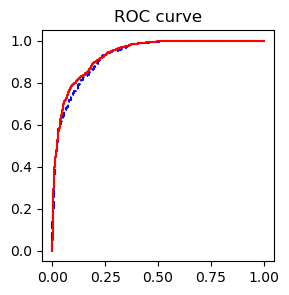

In [35]:
fpr_test, tpr_test, th_test = metrics.roc_curve(test.churn, test.proba)
fpr_train, tpr_train, th_train = metrics.roc_curve(train.churn, train.proba)

plt.figure(figsize=[3, 3])
plt.plot(fpr_test, tpr_test, 'b--')
plt.plot(fpr_train, tpr_train, 'r-')
plt.title('ROC curve')
plt.show()

In [36]:
print('AUC = %.4f' %metrics.auc(fpr_test, tpr_test))

AUC = 0.9297


In [37]:
#最优阈值
th_test[(tpr_test - fpr_test).argmax()]

0.3562514991466361

In [32]:
test['prediction'] = (test['proba'] > 0.456).astype('int')
pd.crosstab(test.churn, test.prediction, margins=True)

prediction,0,1,All
churn,,,
0.0,456,104,560
1.0,68,411,479
All,524,515,1039


## 模型优化

In [39]:
# 方差膨胀因子检测
def vif(df, col_i):
    from statsmodels.formula.api import ols
    
    cols = list(df.columns)
    cols.remove(col_i)
    cols_noti = cols
    formula = col_i + '~' + '+'.join(cols_noti)
    r2 = ols(formula, df).fit().rsquared
    return 1. / (1. - r2)

In [40]:
exog = train[candidates].drop(['churn'], axis=1)
for i in exog.columns:
    print(i, '\t', vif(df=exog, col_i=i))

duration 	 1.043650231193792
AGE 	 1.061106306219031
incomeCode 	 1.01525593193185
nrProm 	 1.0018840842195391
peakMinAv 	 1.0461668630867544
peakMinDiff 	 1.0187447997918488
call_10086 	 1.0213331858803


In [41]:
#分类变量的相关性检验
#最终模型的显著性检验